# Student Performance: Data Analysis

**Dataset:** Student Performance Dataset<sup>[1]</sup> with 395 students and 33 columns covering school, demographics, study habits, absences and grades (G1, G2, G3).

**Goal:** Explore the data, find the average, highest and lowest marks, count passed and failed students, and look for patterns using visualizations.

<sup>[1] Source: [Student Performance Dataset (Kaggle)](https://www.kaggle.com/code/mohamedredaibrahim/student-performance-dataset/input), 767 upvotes, published in 2024.</sup>

## Final Conclusion and Insights

**Key numbers**
- Average marks: 32.0 out of 60
- Highest marks: 58
- Lowest marks: 4
- No of Students who passed: 340(86.1%)
- No of Students who failed: 55(13.9%)

The average student scores a little above the pass mark (19.8 out of 60), and most results sit in the middle with a few students at the low end.

A small group of students dropped out before the final exam. Their grades were already falling and their absences were never recorded, so they hide the real pattern when included.

Most students are 15 to 18 years old. The older ones are partly linked to past failures, but not fully.

Once the dropouts are set aside, students who miss more school tend to score a little lower, though the effect is mild and many exceptions exist.

Scroll back up to see how each of these findings was reached.

## Limitations
- The pass mark (19.8 out of 60) is my assumption, not part of the dataset.
- Results for 2 to 3 failures and for very high absences rest on very few students.
- The `abs_group` cut points are my own choice.
- `total` for dropouts uses only G1 and G2, since G3 is 0.

## Further Experiments
1. Check whether `studytime` and `failures` affect total marks (box plots).
2. Compare `higher`, `internet` and `nursery` (yes vs no) against total.
3. Compare the two schools (GP vs MS) and the two sexes on total marks.
4. Draw a correlation heatmap of the numeric columns.
5. Track the G1 → G2 → G3 change to see who improves and who drops.
6. Run a t-test to check whether the difference in marks between absence groups is statistically significant.
7. Repeat the analysis with a different pass mark (for example 50% of G3 only) and see whether the results change.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

## Data Handelling

In [2]:
df = pd.read_csv('student_data.csv')
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


### No null values

In [3]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

### No duplicate values

In [4]:
df.duplicated().sum()

np.int64(0)

### Information of the Dataset

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

### New dataset will contain school, sex, age, studytime, nursery, higher, internet, health, absences, faliures and grades removing unnecessary columns 

In [6]:
cols = ["school", "sex", "age", "studytime", "nursery",
        "higher", "internet", "health", "absences", 'failures', 'G1', 'G2', 'G3']
df = df[cols]            

In [7]:
df

,school,sex,age,studytime,nursery,higher,internet,health,absences,failures,G1,G2,G3
0,GP,F,18,2,yes,yes,no,3,6,0,5,6,6
1,GP,F,17,2,no,yes,yes,3,4,0,5,5,6
2,GP,F,15,2,yes,yes,yes,3,10,3,7,8,10
3,GP,F,15,3,yes,yes,yes,5,2,0,15,14,15
4,GP,F,16,2,yes,yes,no,5,4,0,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,2,yes,yes,no,4,11,2,9,9,9
391,MS,M,17,1,no,yes,yes,2,3,0,14,16,16
392,MS,M,21,1,no,yes,no,3,3,3,10,8,7
393,MS,M,18,1,no,yes,yes,5,0,0,11,12,10


In [8]:
# Adding up the total marks
warnings.filterwarnings('ignore')
df["total"] = df["G1"] + df["G2"] + df["G3"]

In [9]:
df

,school,sex,age,studytime,nursery,higher,internet,health,absences,failures,G1,G2,G3,total
0,GP,F,18,2,yes,yes,no,3,6,0,5,6,6,17
1,GP,F,17,2,no,yes,yes,3,4,0,5,5,6,16
2,GP,F,15,2,yes,yes,yes,3,10,3,7,8,10,25
3,GP,F,15,3,yes,yes,yes,5,2,0,15,14,15,44
4,GP,F,16,2,yes,yes,no,5,4,0,6,10,10,26
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,2,yes,yes,no,4,11,2,9,9,9,27
391,MS,M,17,1,no,yes,yes,2,3,0,14,16,16,46
392,MS,M,21,1,no,yes,no,3,3,3,10,8,7,25
393,MS,M,18,1,no,yes,yes,5,0,0,11,12,10,33


### 5 object(str) columns and 9 integer columns

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   school     395 non-null    object
 1   sex        395 non-null    object
 2   age        395 non-null    int64 
 3   studytime  395 non-null    int64 
 4   nursery    395 non-null    object
 5   higher     395 non-null    object
 6   internet   395 non-null    object
 7   health     395 non-null    int64 
 8   absences   395 non-null    int64 
 9   failures   395 non-null    int64 
 10  G1         395 non-null    int64 
 11  G2         395 non-null    int64 
 12  G3         395 non-null    int64 
 13  total      395 non-null    int64 
dtypes: int64(9), object(5)
memory usage: 43.3+ KB


## EDA

### From this Distinct value analysis this is clear in this new dataset have no worries about captial or small letters. Clearly visible in every column there are two different values present

In [11]:
print("Distincct schools in the dataset-\n ", df['school'].unique())
print("Gender- \n", df['sex'].unique())
print("In nursery Class- \n", df['nursery'].unique())
print("Higher Class- \n", df['higher'].unique())
print("User of Internet-\n ", df['internet'].unique())

Distincct schools in the dataset-
  ['GP' 'MS']
Gender- 
 ['F' 'M']
In nursery Class- 
 ['yes' 'no']
Higher Class- 
 ['yes' 'no']
User of Internet-
  ['no' 'yes']


In [12]:
df.describe()

,age,studytime,health,absences,failures,G1,G2,G3,total
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.035443,3.554430,5.708861,0.334177,10.908861,10.713924,10.415190,32.037975
std,1.276043,0.839240,1.390303,8.003096,0.743651,3.319195,3.761505,4.581443,11.090357
min,15.000000,1.000000,1.000000,0.000000,0.000000,3.000000,0.000000,0.000000,4.000000
25%,16.000000,1.000000,3.000000,0.000000,0.000000,8.000000,9.000000,8.000000,25.000000
50%,17.000000,2.000000,4.000000,4.000000,0.000000,11.000000,11.000000,11.000000,32.000000
75%,18.000000,2.000000,5.000000,8.000000,0.000000,13.000000,13.000000,14.000000,40.000000
max,22.000000,4.000000,5.000000,75.000000,3.000000,19.000000,19.000000,20.000000,58.000000


**Useful findings from the dataset description**

1. Student age ranges from 15 to 22.
2. Study time is coded 1 to 4 (1 = lowest, 4 = highest weekly study time).
3. Students with 0 absences are present, as well as a student with 75 days of absence.
4. G2 and G3 have a minimum of 0 (G1 minimum is 3). These may be dropouts or skipped exams, so check them.
5. The remaining columns (G1, G2, G3 and total) look fine, and we can check them with plots for better understanding.

**Future Search**

1. The 75th percentile of age is 18, meaning 75% of students are 18 or younger. Why is the max 22? Is it an outlier, or can it be connected with failures?
2. Plot absences vs total. Does total change as absences increase?
3. The 75th percentile of absences is 8, so 75% of students were absent 8 days or fewer. Why is the max 75? Is it an outlier or a data error? Need to investigate.

In [13]:
df['failures'].unique()

array([0, 3, 2, 1])

Most students have 0 failures, only a few have 1 to 3. Students with more failures may be older, so I’ll check mean age by failures.

In [14]:
print(df.groupby("failures")["age"].mean())

failures
0    16.506410
1    17.520000
2    16.941176
3    17.562500
Name: age, dtype: float64


<Axes: title={'center': 'age'}, xlabel='failures'>

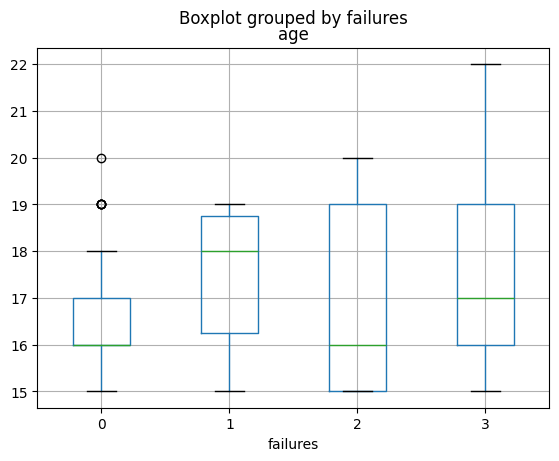

In [15]:
df.boxplot(column="age", by="failures")

Failures are associated with higher age (mainly 0 vs 1), but the pattern is not consistent for 2 and 3 failures, and some older students have 0 failures. So failures partly explain the age gap, not fully. My hypothesis is partially correct

In [16]:
print(df[df["G3"] == 0][["G1", "G2", "G3", "absences"]].describe())

              G1         G2    G3  absences
count  38.000000  38.000000  38.0      38.0
mean    7.526316   4.657895   0.0       0.0
std     1.811925   3.700083   0.0       0.0
min     4.000000   0.000000   0.0       0.0
25%     6.000000   0.000000   0.0       0.0
50%     7.000000   5.000000   0.0       0.0
75%     9.000000   8.000000   0.0       0.0
max    12.000000  10.000000   0.0       0.0


**Findings: students with G3 = 0**

1. **Grades were already falling.** Their G1 mean is 7.5 and G2 drops to 4.7, so these are not normal students who skipped one exam.
2. **Absences are exactly 0 for all 38** (mean, std, min and max are all 0). This is not a real attendance record. A student with 0 absences and G3 = 0 most likely left the course, so the absence count was never recorded.
3. **The 75-day student is not in this group**, because the absences max here is 0. That outlier is a separate case.

### Main Findings:

**1. Average marks**

In [17]:
print("Average:", df["total"].mean())

Average: 32.037974683544306


**2. Highest marks**

In [18]:
print("Highest:", df["total"].max())

Highest: 58


**3. Lowest marks**

In [19]:
print("Lowest :", df["total"].min())

Lowest : 4


**4. Number of students who passed** (pass mark = 33.0% of 60)

In [20]:
df["result"] = (df["total"] >= 19.8).map({True: "Pass", False: "Fail"})
print(df["result"].value_counts())
warnings.filterwarnings('ignore')

result
Pass    340
Fail     55
Name: count, dtype: int64


## Data Visualization 

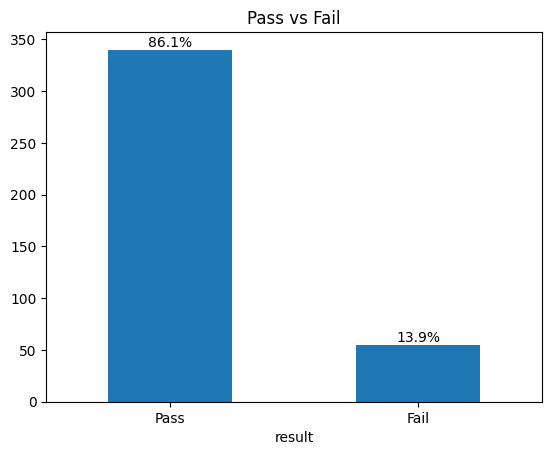

In [21]:
# Barplot of Pass vs Fail
ax = df["result"].value_counts().plot(kind="bar", rot=0, title="Pass vs Fail")
ax.bar_label(ax.containers[0], labels=[f"{v:.1f}%" for v in df["result"].value_counts(normalize=True)*100])
plt.savefig("pass_fail")
plt.show()

**Conclusion: Pass vs Fail**

- More students passed than failed (pass mark = 19.8 out of 60), so the overall success rate is higher than the failure rate.
- Passed: 340 students (86%), Failed: 55 students (14%).

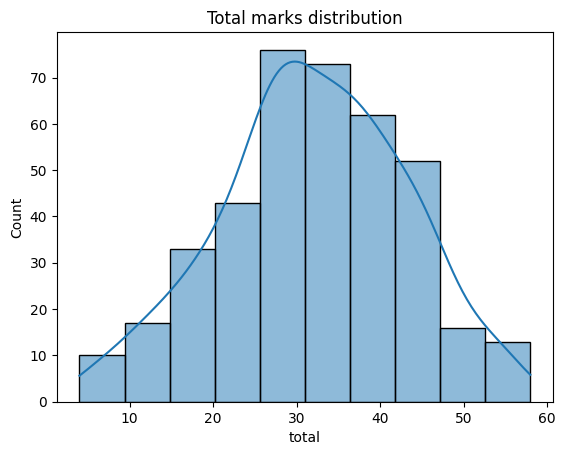

In [22]:
# Total Marks distribution plot
sns.histplot(df["total"],bins=10, kde=True)
plt.title("Total marks distribution")
plt.savefig("marks_distribution")
plt.show()


**Conclusion: Total marks distribution**

- The distribution is almost normal, with most students scoring between 25 and 45.
- It is slightly left-skewed: a small group of students has much lower marks (below 25), which creates a longer tail on the left side.
- The peak is around 30, close to the mean (32.0), so the average represents a typical student well.

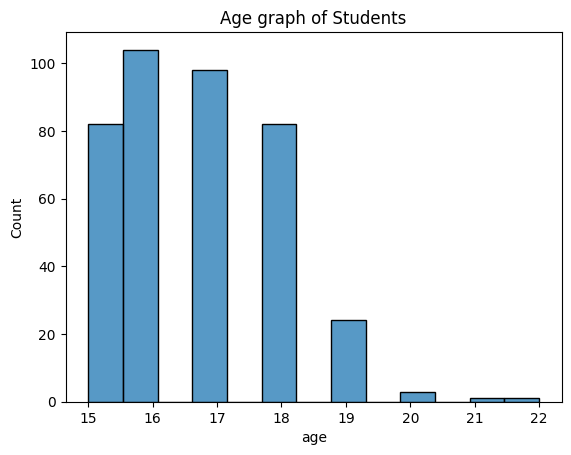

In [23]:
# Which Age is more and which is less by barplot 
sns.histplot(df["age"])
plt.title("Age graph of Students")
plt.savefig("age_graph")
plt.show()


**Conclusion: Age graph of Students**

- Most students are between 15 and 18 years old, with the peak at 16 to 17, so the typical student age is about 16 to 17.
- Very few students are 20 to 22 years old. They may be students who repeated classes or started school late (failures partly explain this, as seen earlier).

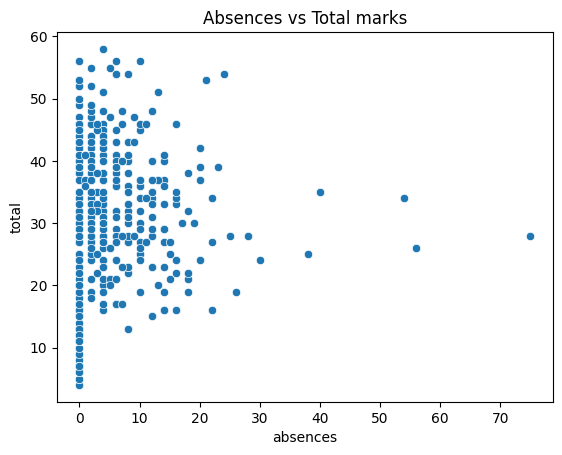

-0.005908806132303003


In [24]:
# Plot absences vs total marks
sns.scatterplot(data=df, x="absences", y="total")
plt.title("Absences vs Total marks")
plt.savefig('absenst_vs_TotalMarks')
plt.show()
print(df["absences"].corr(df["total"]))


**Conclusion: Absences vs Total marks**

- The correlation between absences and total marks is about -0.006, so there is no clear linear pattern. Total marks do not rise or fall as absences increase.
- Students with similar absences have very different totals (for example, 0 to 10 absences cover totals from about 5 to 58), so absences alone do not explain marks.
- The column at 0 absences includes many low totals. These are likely the 38 dropouts (G3 = 0), whose absence count was recorded as 0.
- A few students with very high absences (above 30, up to 75) are outliers. They do not change the overall pattern.

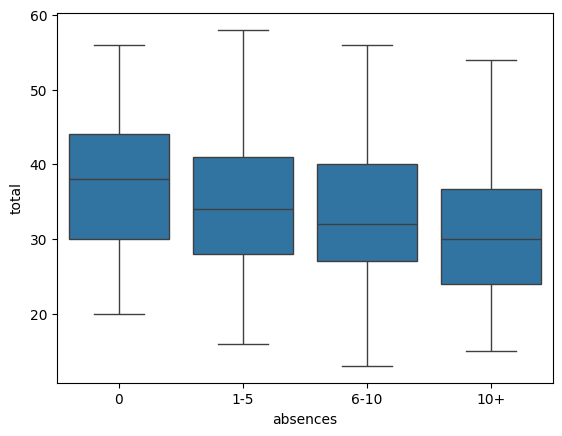

In [25]:
active = df[df["G3"] != 0]
sns.boxplot(x=pd.cut(active["absences"], bins=[-1, 0, 5, 10, 80], labels=["0", "1-5", "6-10", "10+"]), y=active["total"])
plt.show()

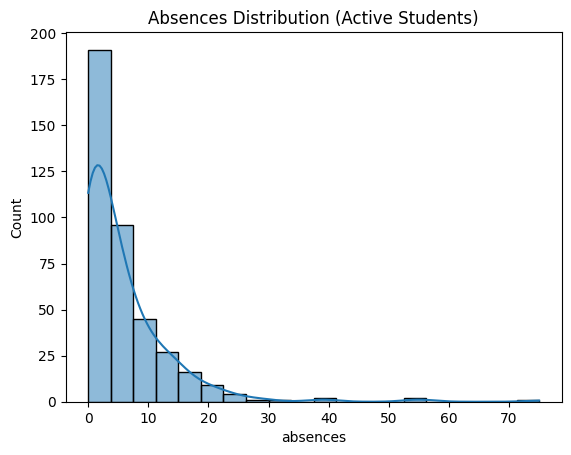

In [26]:
#
sns.histplot(data=df, x="absences",kde=True, bins=20)
plt.title("Absences Distribution (Active Students)")
plt.savefig("Absesnces_distribution")
plt.show()

**Conclusion: Absences Distribution (Active Students)**

- The distribution is strongly right-skewed: most students have 0 to 10 absences, and the count drops quickly as absences increase.
- Very few students have more than 30 absences (up to 75), so they are outliers.

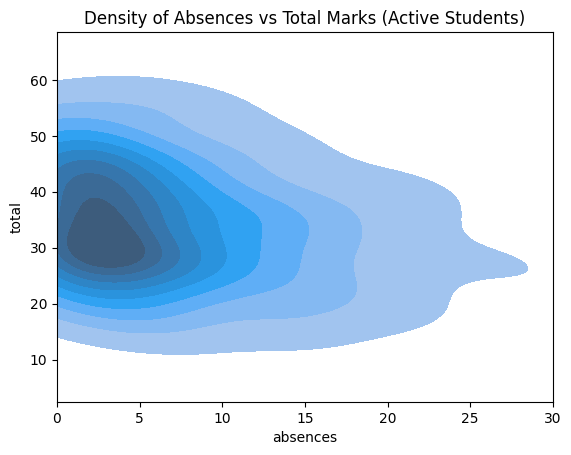

In [27]:
sns.kdeplot(data=active, x="absences", y="total", fill=True)
plt.xlim(0, 30)
plt.title("Density of Absences vs Total Marks (Active Students)")
plt.savefig("Densiy_plot_of_Absences_VS_TotalMarks")
plt.show()

**Conclusion: Absences vs Total marks (active students only, G3 ≠ 0)**

- After removing the 38 dropouts (G3 = 0), a mild negative pattern appears: the median total falls from about 38 (0 absences) to about 30 (10+ absences).
- Most active students have 0 to 10 absences and totals between 25 and 40 (darkest area of the density plot).
- The groups overlap a lot, so absences affect marks only a little. Many students with high absences still score well.
- The dropouts hid this pattern in the full data because all of them have 0 absences and low marks.